
Data: US Social Security Administration (SSA), national baby names 1880–2025
(https://www.ssa.gov/oact/babynames/limits.html). One file `yobYYYY.txt` per year with columns
`name, sex, count`; names given to fewer than 5 babies in a year are not published.


In [9]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [10]:
%pip install -q numpy pandas scipy matplotlib

In [11]:
import io, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## 1. Load the data



In [13]:

def load_names(zip_path="/content/drive/MyDrive/names.zip", data_dir="data/names"):
    data_dir = Path(data_dir)
    if not any(data_dir.glob("yob*.txt")):
        data_dir.mkdir(parents=True, exist_ok=True)
        zipfile.ZipFile(zip_path).extractall(data_dir)

    frames = []
    for path in sorted(data_dir.glob("yob*.txt")):
        df = pd.read_csv(path, header=None, names=["name", "sex", "count"])
        df["year"] = int(path.stem[3:])
        frames.append(df)
    names = pd.concat(frames, ignore_index=True)

    names["rank"] = (names.groupby(["year", "sex"])["count"].rank(method="first", ascending=False).astype(int))
    names["share"] = names["count"] / names.groupby(["year", "sex"])["count"].transform("sum")
    return names

names = load_names()
print(f"{len(names):,} rows, years {names.year.min()}–{names.year.max()}")
print(names.groupby("sex").size()) #кількість імен а не дітей
names[names.year == 2025].groupby("sex").head(5)

2,181,032 rows, years 1880–2025
sex
F    1280901
M     900131
dtype: int64


,name,sex,count,year,rank,share
2149805,Olivia,F,13544,2025,1,0.008427
2149806,Charlotte,F,13400,2025,2,0.008337
2149807,Emma,F,12754,2025,3,0.007935
2149808,Amelia,F,12699,2025,4,0.007901
2149809,Sophia,F,12561,2025,5,0.007815
2167102,Liam,M,20818,2025,1,0.012188
2167103,Noah,M,20358,2025,2,0.011919
2167104,Oliver,M,14939,2025,3,0.008746
2167105,Theodore,M,13355,2025,4,0.007819
2167106,Henry,M,12020,2025,5,0.007037


## 2. Descriptive statistics for 2025

The unit of observation is one name in one year: `count` is how many babies got that name.
Skewness and kurtosis are the sample (bias-corrected) versions. We report kurtosis in the
Pearson form (normal distribution = 3) and the excess (normal = 0).

Why `ddof=1` and `bias=False`. Our counts are treated as a sample, so we use estimators
corrected for sample size rather than the plain "population" formulas.

- Standard deviation. `ddof=1` divides by $n-1$ instead of $n$:
  $s^2 = \frac{1}{n-1}\sum_i (x_i - \bar x)^2$.
  dividing by $n-1$ makes $s^2$ an unbiased estimator of $\sigma^2$
- Skewness and kurtosis. The plain moment estimators
  $g_1 = \frac{m_3}{m_2^{3/2}}$ and $g_2 = \frac{m_4}{m_2^2} - 3$, where $m_k = \frac{1}{n}\sum_i (x_i-\bar x)^k$,
  are biased in small samples. With `bias=False`, scipy applies the standard adjustment. These are bias-corrected rather than exactly unbiased.
- The real uncertainty in our skewness and
  kurtosis comes not from sample size but from the heavy tail (see the reading below), which no
  small-sample correction can fix.

In [15]:
def describe_counts(x):
    x = np.asarray(x, dtype=float)
    p = x / x.sum()
    return pd.Series({
        "distinct names": len(x),
        "total births": x.sum(),
        "mean": x.mean(),
        "median": np.median(x),
        "sd": x.std(ddof=1),
        "skewness": stats.skew(x, bias=False),
        "kurtosis (normal = 3)": stats.kurtosis(x, fisher=False, bias=False),
        "excess kurtosis": stats.kurtosis(x, fisher=True, bias=False),
        "share of names with count < 20, %": 100 * (x < 20).mean(),
        "top-10 share of births, %": 100 * np.sort(x)[::-1][:10].sum() / x.sum(),
        "Shannon entropy, bits": -(p * np.log2(p)).sum(),})

def summary_table(names, year):
    d = names[names.year == year]
    return pd.DataFrame({
        "Girls": describe_counts(d.loc[d.sex == "F", "count"]),
        "Boys":  describe_counts(d.loc[d.sex == "M", "count"]),})

summary_table(names, 2025).round(2)

,Girls,Boys
distinct names,17297.00,13930.00
total births,1607267.00,1708076.00
mean,92.92,122.62
median,12.00,12.00
sd,473.00,658.58
skewness,14.05,13.24
kurtosis (normal = 3),274.95,254.00
excess kurtosis,271.95,251.00
"share of names with count < 20, %",64.65,63.79
"top-10 share of births, %",6.99,7.98



- **Mean vs median.** Half of all names were given to 12 babies or fewer (median = 12), while the
  mean is 93 for girls and 123 for boys. The mean is pulled up by a few very popular names with
  10–15 thousand bearers each, so it does not describe a "typical" name; the median does.
- **Heavy right tail.** Skewness is about 14 and kurtosis about 250–275, versus 0 and 3 for a
  normal distribution. Counts span several orders of magnitude (from 5 to ~15,000), so a normal
  or any other light-tailed model is clearly inappropriate.
- **Nuance: these moments are not stable.** Skewness and kurtosis use the 3rd and 4th powers of
  deviations, so with such a heavy tail they are driven by a handful of the largest names rather
  than by the bulk of the data: the single most popular name alone accounts for a large part of
  the kurtosis. Adding or removing a few top names would change them a lot. So these values show
  *that* the right tail is heavy, not a precise, stable parameter of the distribution.
- **Most names are rare.** About 64% of names have fewer than 20 bearers, and the top-10 names
  cover only 7–8% of births (later we will do it for other years).
  SSA drops names with fewer than 5 babies, so the true tail is even longer.
- **Girls' names are more diverse.** Fewer girls than boys were born (1.61M vs 1.71M), yet girls
  received more distinct names (17,297 vs 13,930). Entropy is 11.05 vs 10.43 bits, i.e. the
  diversity of about $2^{11.05} \approx 2100$ vs $2^{10.43} \approx 1400$ equally popular names.
- **What this motivates.** A heavy tail of this kind is typical of power-law (Zipf) data, where parents choose names they hear, and popular names are heard
  more often. However, a heavy tail is consistent with Zipf's law, not a proof of it.

## 3. Histogram on a log scale

Counts range from 5 to about 15,000, so equal-width bins would put
almost all names into the first bar. We therefore use 40 logarithmic bins: each bin is about 22%
wider than the previous one, so all bins look equally wide on a
log scale. Both axes are logarithmic.

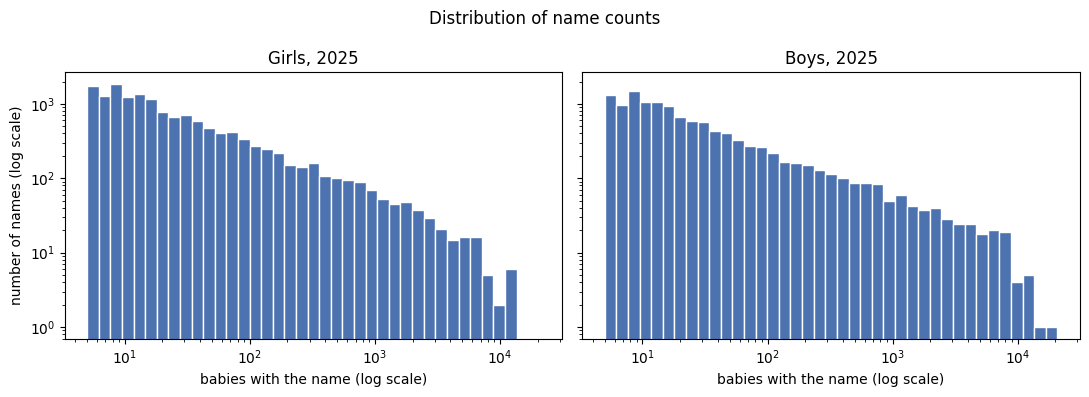

In [16]:
def plot_count_histogram(names, year):
    d = names[names.year == year]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    bins = np.logspace(np.log10(5), np.log10(d["count"].max()), 40)
    for ax, (sex, label) in zip(axes, [("F", "Girls"), ("M", "Boys")]):
        ax.hist(d.loc[d.sex == sex, "count"], bins=bins, color="#4C72B0", edgecolor="white")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(f"{label}, {year}")
        ax.set_xlabel("babies with the name (log scale)")
    axes[0].set_ylabel("number of names (log scale)")
    fig.suptitle("Distribution of name counts")
    plt.tight_layout(); plt.show()
plot_count_histogram(names, 2025)

Most names are rare and very few are popular: the tallest bars are at the very left
(names given to 5–10 babies), and the bars only decrease towards the right, where a handful of names
have around 10,000 bearers.

The decline looks roughly uniform across the whole range: each tenfold increase in popularity seems
to reduce the number of such names by a similar factor, so on log–log axes the bar tops lie close to
a straight line. Such "same rule at every scale" behaviour is typical of a power law.

This is a visual impression, not a test. We estimate the slope and test the power-law hypothesis formally in H1.

## 4. log(rank) vs log(count): first look at Zipf's law


Sort the names of one year by popularity and give them ranks: $r = 1$ for the most
popular name, $r = 2$ for the next, and so on. Each dot is one name: $x$ = its rank $r$,
$y$ = its count $f(r)$ (number of babies). Both axes are logarithmic.

Zipf's law is a power law for these counts:

$$f(r) = \frac{C}{r^{\alpha}}, \qquad r = 1, 2, \dots$$

- $C$ is the count of the top name (rank 1);
- $\alpha > 0$ is the exponent: how fast popularity falls with rank. With $\alpha = 1$ ("classic"
  Zipf) the 10th name is 10 times rarer than the 1st, the 100th is 100 times rarer.

Taking logarithms gives a straight line:

$$\log f(r) = \log C - \alpha \log r,$$

so if the law holds, the dots lie on a straight line with slope $-\alpha$.

The dashed lines are least-squares (OLS) fits of $\log f$ on $\log r$, one per sex; their slope is
a rough estimate of $-\alpha$. It is only a visual guide: OLS treats all points equally, so the thousands
of rare names dominate the fit, and it gives no valid test. In H1 we estimate $\alpha$ by maximum
likelihood and test the fit with a Kolmogorov–Smirnov test.

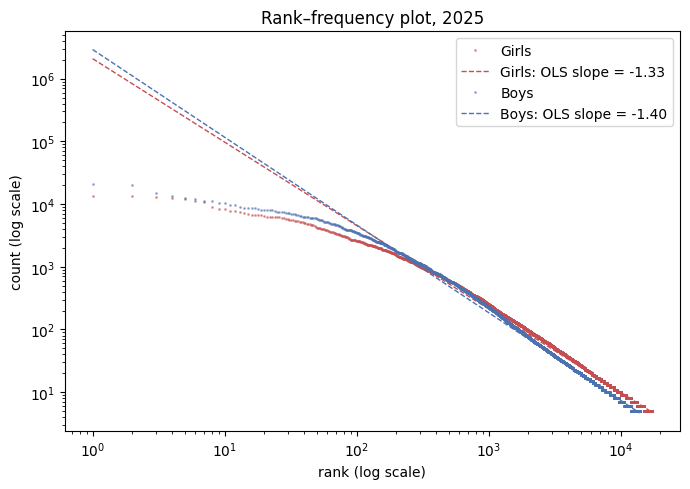

,name,sex,count,year,rank,share
2149805,Olivia,F,13544,2025,1,0.008427
2149814,Eliana,F,8191,2025,10,0.005096
2149904,Juniper,F,2618,2025,100,0.001629
2167102,Liam,M,20818,2025,1,0.012188
2167111,Lucas,M,10219,2025,10,0.005983
2167201,Myles,M,3511,2025,100,0.002056


In [18]:
def plot_rank_frequency(names, year):
    d = names[names.year == year]
    fig, ax = plt.subplots(figsize=(7, 5))
    slopes = {}
    for sex, label, color in [("F", "Girls", "#C44E52"), ("M", "Boys", "#4C72B0")]:
        s = d[d.sex == sex].sort_values("rank")
        log_rank, log_count = np.log10(s["rank"]), np.log10(s["count"])
        ax.plot(s["rank"], s["count"], ".", ms=2, color=color, alpha=0.5, label=label)
        fit = stats.linregress(log_rank, log_count)
        slopes[label] = round(fit.slope, 3)
        ax.plot(s["rank"], 10 ** (fit.intercept + fit.slope * log_rank), "--", color=color,
                lw=1, label=f"{label}: OLS slope = {fit.slope:.2f}")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("rank (log scale)"); ax.set_ylabel("count (log scale)")
    ax.set_title(f"Rank–frequency plot, {year}")
    ax.legend(); plt.tight_layout(); plt.show()
    return slopes

plot_rank_frequency(names, 2025)
names[(names.year == 2025) & (names["rank"].isin([1, 10, 100]))]

The points do not lie on a single straight line, so Zipf's law does not hold for all names.

- **Head (ranks 1 to about 100):** the curve is much flatter than a power law. For girls the top name
  (Olivia, 13,544 babies) is only 1.7 times as popular as rank 10 (Eliana, 8,191) and 5.2 times as
  popular as rank 100 (Juniper, 2,618); for boys the ratios are 2.0 (Liam 20,818 vs Lucas 10,219) and
  5.9 (vs Myles, 3,511). Classic Zipf's law with α = 1 would predict ratios of 10 and 100, so popularity
  at the top is spread much more evenly than the law predicts.
- **Tail (ranks from about 200 to about 17,000):** the points are close to a straight line, which is
  consistent with a power law in this range. The OLS slope is −1.33 for girls and −1.40 for boys,
  steeper than the classic Zipf value of −1.
- **Horizontal steps at the bottom right:** hundreds of names share the same small integer count
  (5, 6, 7, …), so they appear as flat rows of points.
- **Why the OLS line misses the head:** the fit gives every point equal weight, and thousands of tail
  points outweigh the few top names, so the line follows the tail. It is a visual guide only and
  not a valid estimate of α.

So the hypothesis worth testing is not "exact Zipf for all names" but "a power law for names below
some rank (above some minimum count)".